# Test-set results and failure analysis (one test run)

**Read-only.** This notebook only reads saved files from the one test run (2026-11-19). It fits no model, computes
no new metric and does not load the test set.

| Source | Made by |
|---|---|
| `artifacts/results/final/` (metrics, predictions, tables) | `scripts/final_test.py --test` (once), `scripts/test_analysis.py` |
| `artifacts/figures/report/test_*.png` | `scripts/test_analysis.py` |
| `artifacts/figures/failure_test/*.png` (attention maps) | `scripts/test_attention.py` (visualization only; networks checked against `vectors.npz`) |

Run: `uv run --group notebooks jupyter nbconvert --to notebook --execute --inplace notebooks/test_failure_analysis.ipynb`

In [1]:
import json
import pandas as pd
from IPython.display import Image, Markdown, display
from luad.config import repo_path

pd.set_option("display.precision", 3); pd.set_option("display.width", 160)
FINAL = repo_path("artifacts/results/final")
FIG = repo_path("artifacts/figures")
CLASSES = ["Acinar", "Cribriform", "In situ", "Lepidic", "Micropapillary", "Papillary", "Solid"]
summary = json.loads((FINAL / "summary.json").read_text())
{k: summary[k] for k in ["best_single_meta", "crossfit_seed", "classifier_seed", "bootstrap", "bootstrap_seed"] if k in summary}

{'best_single_meta': 'uni2h+meta',
 'crossfit_seed': 15030,
 'classifier_seed': 30,
 'bootstrap': 2000,
 'bootstrap_seed': 30}

## 0. Integrity: test access log and the attention-network check

In [2]:
print(repo_path("artifacts/logs/test_access.log").read_text())
pd.read_csv(FINAL / "test_attention_check.csv")

{"time": "2026-11-19T21:55:13", "split_file": "artifacts/splits/split_seed30.csv", "reason": "final evaluation of the locked v7 rows and fused model (scripts/final_test.py)"}
{"time": "2026-11-20T16:24:49", "split_file": "artifacts/splits/split_seed30.csv", "reason": "visualization only: attention maps of the final networks, retrained with the final cross-fit seed and checked against vectors.npz; no classifier fit, no metric (scripts/test_attention.py)"}



,model,split,max_abs_diff
0,uni2h,dev,0.0
1,uni2h,test,0.0
2,hoptimus1,dev,0.0
3,hoptimus1,test,0.0
4,joint,dev,0.0
5,joint,test,0.0


## 1. Required comparison table (README §5.3)

95% CIs: 2,000 bootstrap resamples of the 42 test patients, stratified by class, seed 30.

In [3]:
display(Markdown((FINAL / "table.md").read_text()))

| Configuration | Test macro AUROC [95% CI] | Test balanced acc. [95% CI] | CV AUROC (mean ± SD) | Nested-CV AUROC |
|---|---|---|---|---|
| Metadata only (age + sex) | 0.672 [0.569, 0.767] | 0.309 [0.190, 0.446] | 0.599 ± 0.061 | 0.600 |
| UNI2-h alone (ABMIL) | 0.880 [0.809, 0.943] | 0.589 [0.465, 0.703] | 0.867 ± 0.034 | 0.863 |
| Virchow2 alone (Prism2) | 0.873 [0.812, 0.929] | 0.492 [0.360, 0.640] | 0.862 ± 0.030 | 0.843 |
| H-optimus-1 alone (ABMIL) | 0.889 [0.836, 0.932] | 0.538 [0.399, 0.671] | 0.863 ± 0.034 | 0.880 |
| Best single + meta (UNI2-h + meta) | 0.910 [0.852, 0.960] | 0.642 [0.500, 0.787] | 0.870 ± 0.035 | 0.850 |
| **Fused (agent) + meta** | 0.918 [0.866, 0.960] | 0.568 [0.429, 0.720] | 0.880 ± 0.025 | 0.867 |


### Paired differences (fused − row), same resamples
`share_resamples_fused_not_better` = share of resamples in which the fused model is not better (one-sided bootstrap check, not a corrected p-value).

In [4]:
paired = pd.read_csv(FINAL / "paired.csv")
paired[paired.metric.isin(["macro_auroc", "balanced_accuracy"])].pivot(index="row", columns="metric",
    values=["fused_minus_row", "ci_low", "ci_high"]).round(3)

fused_minus_row                        ci_low                       ci_high            
metric         balanced_accuracy macro_auroc balanced_accuracy macro_auroc balanced_accuracy macro_auroc
row                                                                                                     
hoptimus1                  0.030       0.029            -0.116       0.005             0.170       0.057
hoptimus1+meta             0.058       0.024            -0.066       0.000             0.186       0.051
meta                       0.259       0.245             0.052       0.138             0.475       0.359
uni2h                     -0.021       0.038            -0.171       0.004             0.143       0.074
uni2h+meta                -0.074       0.007            -0.268      -0.017             0.140       0.032
virchow2                   0.076       0.045            -0.047       0.005             0.205       0.084
virchow2+meta              0.076       0.042            -0.047       0.003             0.205       0.081

### All metrics with CIs

In [5]:
m = pd.read_csv(FINAL / "metrics.csv")
m.assign(ci=m.apply(lambda r: f"{r.value:.3f} [{r.ci_low:.3f}, {r.ci_high:.3f}]", axis=1)).pivot(index="row", columns="metric", values="ci")

metric,accuracy,balanced_accuracy,macro_auroc,macro_f1
row,,,,
fused,"0.619 [0.476, 0.762]","0.568 [0.429, 0.720]","0.918 [0.866, 0.960]","0.565 [0.408, 0.710]"
hoptimus1,"0.571 [0.429, 0.691]","0.538 [0.399, 0.671]","0.889 [0.836, 0.932]","0.509 [0.371, 0.634]"
hoptimus1+meta,"0.548 [0.429, 0.667]","0.510 [0.374, 0.641]","0.894 [0.840, 0.937]","0.481 [0.346, 0.608]"
meta,"0.357 [0.238, 0.476]","0.309 [0.190, 0.446]","0.672 [0.569, 0.767]","0.285 [0.157, 0.411]"
uni2h,"0.643 [0.524, 0.762]","0.589 [0.465, 0.703]","0.880 [0.809, 0.943]","0.561 [0.432, 0.669]"
uni2h+meta,"0.691 [0.571, 0.809]","0.642 [0.500, 0.787]","0.910 [0.852, 0.960]","0.645 [0.469, 0.786]"
virchow2,"0.524 [0.405, 0.643]","0.492 [0.360, 0.640]","0.873 [0.812, 0.929]","0.472 [0.317, 0.615]"
virchow2+meta,"0.524 [0.405, 0.643]","0.492 [0.360, 0.640]","0.876 [0.816, 0.932]","0.472 [0.317, 0.615]"


## 2. Per-class AUROC (one-vs-rest)

In [6]:
pd.read_csv(FINAL / "per_class_auroc.csv", index_col=0).round(3)

,Acinar,Cribriform,In situ,Lepidic,Micropapillary,Papillary,Solid
meta,0.418,0.637,0.828,0.809,0.746,0.676,0.593
uni2h,0.833,0.897,1.000,0.875,0.870,0.831,0.856
virchow2,0.808,0.914,0.980,0.678,0.957,0.864,0.912
hoptimus1,0.902,0.906,0.986,0.796,0.935,0.824,0.875
uni2h+meta,0.894,0.940,0.997,0.862,0.914,0.860,0.907
virchow2+meta,0.808,0.923,0.983,0.678,0.962,0.864,0.917
hoptimus1+meta,0.902,0.923,0.986,0.803,0.935,0.831,0.880
fused,0.910,0.923,0.986,0.895,0.962,0.846,0.903


## 3. Confusion matrices (counts)

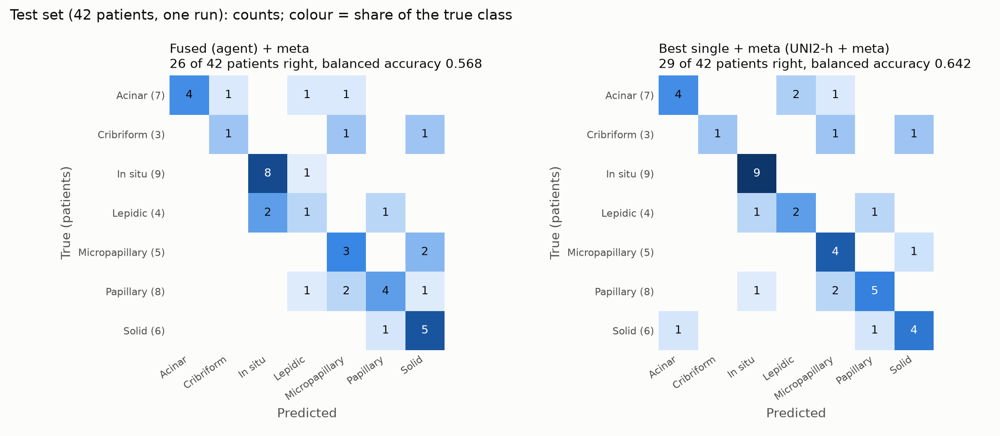

In [7]:
display(Image(filename=str(FIG / "report" / "test_confusion.png"), width=1000))

## 4. Recall per class, upper bound, and accuracy by confidence

Upper bound row = at least one of the 3 image-only models is right for that patient (what a perfect per-patient model choice could reach).

,Acinar,Cribriform,In situ,Lepidic,Micropapillary,Papillary,Solid,BA,n_right
fused,0.57,0.33,0.89,0.25,0.6,0.50,0.83,0.57,26
hoptimus1,0.57,0.67,0.89,0.00,0.6,0.38,0.67,0.54,24
hoptimus1+meta,0.57,0.67,0.89,0.00,0.4,0.38,0.67,0.51,23
meta,0.14,0.33,0.78,0.00,0.2,0.38,0.33,0.31,15
uni2h,0.57,0.00,1.00,0.75,0.8,0.50,0.50,0.59,27
uni2h+meta,0.57,0.33,1.00,0.50,0.8,0.62,0.67,0.64,29
virchow2,0.29,0.33,0.89,0.25,0.6,0.25,0.83,0.49,22
virchow2+meta,0.29,0.33,0.89,0.25,0.6,0.25,0.83,0.49,22
at least 1 of 3 image models right,0.71,0.67,1.00,0.75,0.8,0.50,0.83,0.75,32


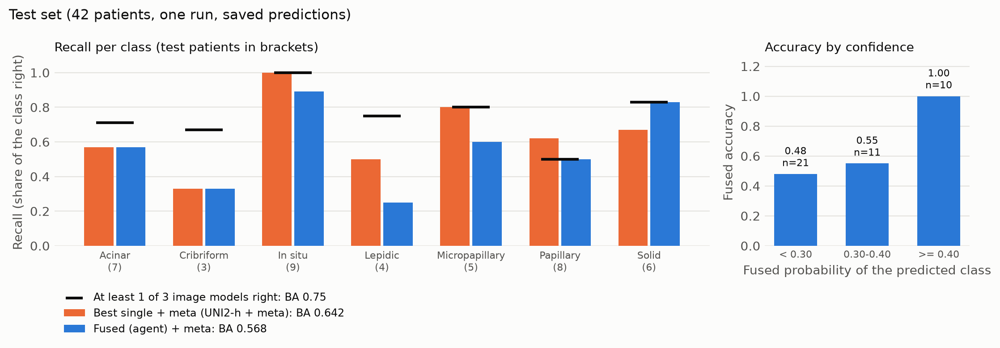

,fused_p_pred,patients,accuracy
0,< 0.30,21,0.48
1,0.30-0.40,11,0.55
2,>= 0.40,10,1.00


In [8]:
display(pd.read_csv(FINAL / "test_recall.csv", index_col=0))
display(Image(filename=str(FIG / "report" / "test_recall.png"), width=1000))
pd.read_csv(FINAL / "test_confidence.csv")

## 5. What the errors have in common

In [9]:
t = pd.read_csv(FINAL / "test_errors.csv", index_col=0)
wrong = t[~t.fused_right]
print(f"fused right: {t.fused_right.sum()} of {len(t)}")
print("fused errors by how many of the 3 single image models are right:", wrong.n_single_right.value_counts().sort_index().to_dict())
best = summary["best_single_meta"]
print(f"right only by fused: {(t.fused_right & ~t[f'{best}_right']).sum()}, right only by {best}: {(~t.fused_right & t[f'{best}_right']).sum()}")
wrong.groupby(["true", "fused_pred"]).size().sort_values(ascending=False).rename("patients").to_frame()

fused right: 26 of 42
fused errors by how many of the 3 single image models are right: {0: 9, 1: 4, 2: 3}
right only by fused: 4, right only by uni2h+meta: 7


patients
true           fused_pred              
Lepidic        In situ                2
Micropapillary Solid                  2
Papillary      Micropapillary         2
Acinar         Lepidic                1
               Cribriform             1
Cribriform     Solid                  1
               Micropapillary         1
Acinar         Micropapillary         1
In situ        Lepidic                1
Lepidic        Papillary              1
Papillary      Lepidic                1
               Solid                  1
Solid          Papillary              1

In [10]:
display(t.groupby("diagnosis").fused_right.agg(["mean", "size"]).round(2))
display(t.groupby(t.n_slides > 1).fused_right.agg(["mean", "size"]).rename_axis("several slides").round(2))
print(f"median fused probability of the predicted class: right {t[t.fused_right].p_pred.median():.2f}, wrong {wrong.p_pred.median():.2f}")

,mean,size
diagnosis,,
AIS,0.89,9
IA,0.53,32
MIA,1.00,1


,mean,size
several slides,,
False,0.58,12
True,0.63,30


median fused probability of the predicted class: right 0.34, wrong 0.27


### Per-class profile

In [11]:
pd.read_csv(FINAL / "test_class_profile.csv", index_col=0)

,patients,fused_recall,share_with_more_slides,median_tiles,median_age,share_female
true,,,,,,
Acinar,7,0.57,0.57,10803.0,54.0,0.57
Cribriform,3,0.33,1.00,18126.0,66.0,0.67
In situ,9,0.89,0.78,6203.0,46.0,0.78
Lepidic,4,0.25,0.50,12708.5,56.0,1.00
Micropapillary,5,0.60,0.80,16698.0,56.0,0.40
Papillary,8,0.50,0.50,10376.5,61.0,0.75
Solid,6,0.83,1.00,15651.5,56.5,0.50


### Every fused error

In [12]:
wrong[["true", "fused_pred", "p_true", "p_pred", "diagnosis", "all_labels", "n_slides", "n_tiles",
       "uni2h_right", "virchow2_right", "hoptimus1_right", f"{best}_right"]].sort_values(["true", "p_pred"])

,true,fused_pred,p_true,p_pred,diagnosis,all_labels,n_slides,n_tiles,uni2h_right,virchow2_right,hoptimus1_right,uni2h+meta_right
WSI-363,Acinar,Lepidic,0.196,0.255,IA,Acinar,1,22630,False,False,False,False
WSI-393,Acinar,Cribriform,0.243,0.268,IA,Acinar,1,10803,True,False,False,True
WSI-288,Acinar,Micropapillary,0.101,0.326,IA,Acinar,2,10413,False,False,False,False
WSI-235,Cribriform,Micropapillary,0.214,0.229,IA,Cribriform,3,18126,False,False,True,True
WSI-245,Cribriform,Solid,0.188,0.375,IA,Cribriform,3,16216,False,False,False,False
WSI-25,In situ,Lepidic,0.153,0.256,AIS,In situ,2,5247,True,True,False,True
WSI-325,Lepidic,Papillary,0.144,0.266,IA,Lepidic,2,11401,False,False,False,False
WSI-370,Lepidic,In situ,0.293,0.297,IA,Lepidic,1,14016,True,True,False,True
WSI-315,Lepidic,In situ,0.319,0.326,IA,Lepidic,3,14302,True,False,False,True
WSI-169,Micropapillary,Solid,0.257,0.291,IA,Micropapillary,3,18304,True,False,True,True


## 6. Example slides with attention maps

Chosen from the saved predictions with the dev notebook's rule: for each main confusion, the 2 most confident
errors, then the most confident correct patient of the true class and of the predicted class.
Heat maps: darker blue = more attention (top 0.5% of tiles darkest). Bottom row: 6 tiles with the most fusion attention.
The maps show where each network puts its weight; they are not proof of what it understood.

### Lepidic called In situ

**Lepidic_called_In_situ_WSI-315**

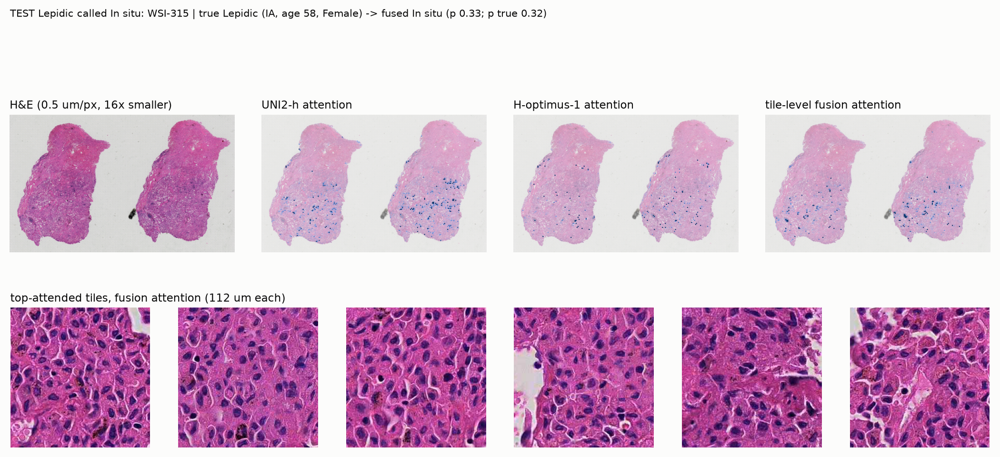

**Lepidic_called_In_situ_WSI-370**

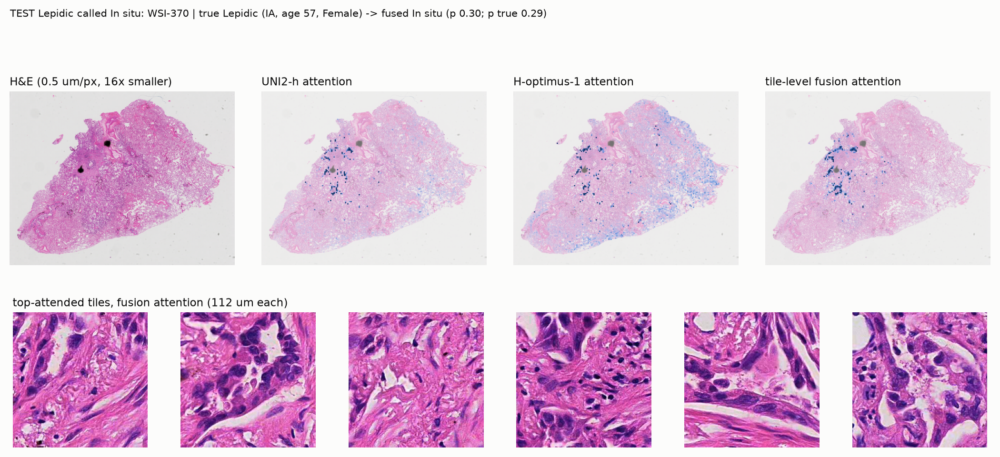

**Lepidic_correct_WSI-364**

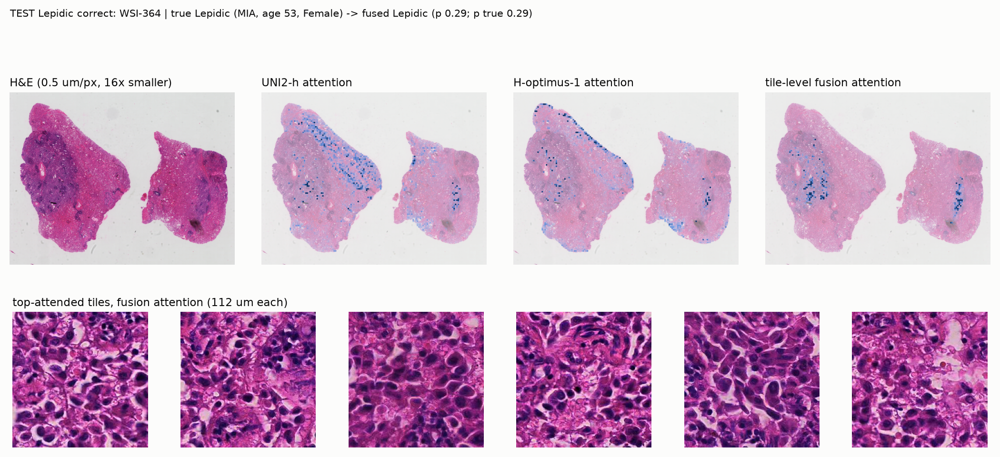

**In_situ_correct_WSI-61**

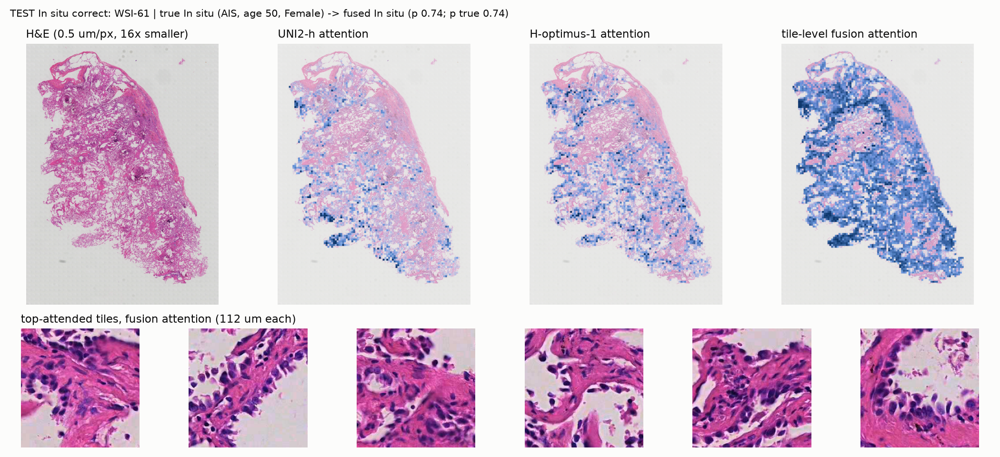

### Papillary called Micropapillary

**Papillary_called_Micropapillary_WSI-174**

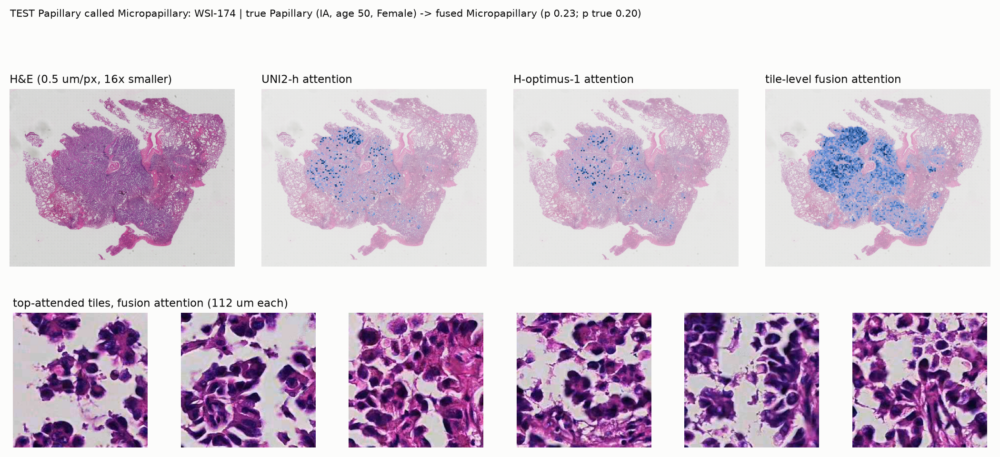

**Papillary_called_Micropapillary_WSI-77**

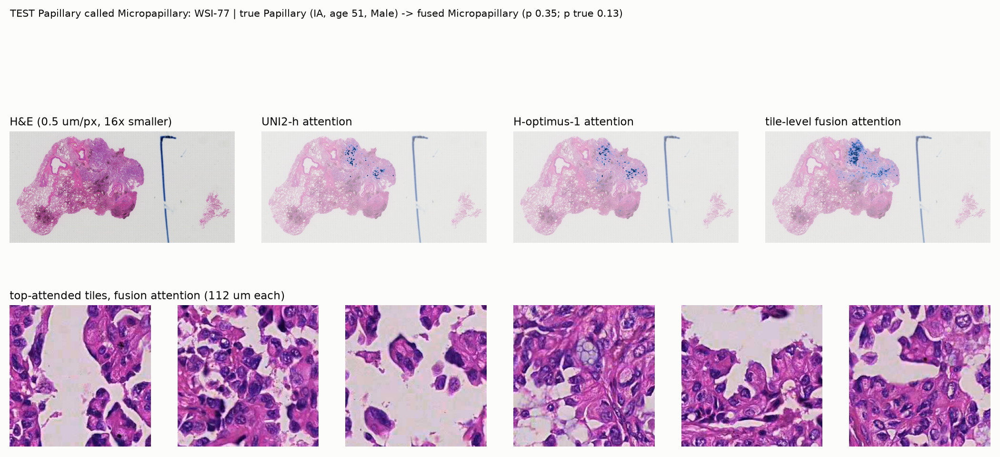

**Papillary_correct_WSI-97**

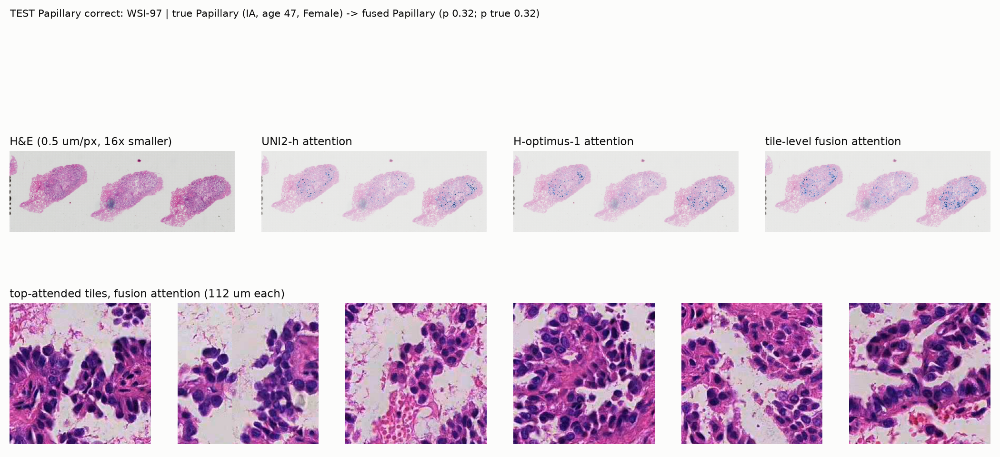

**Micropapillary_correct_WSI-258**

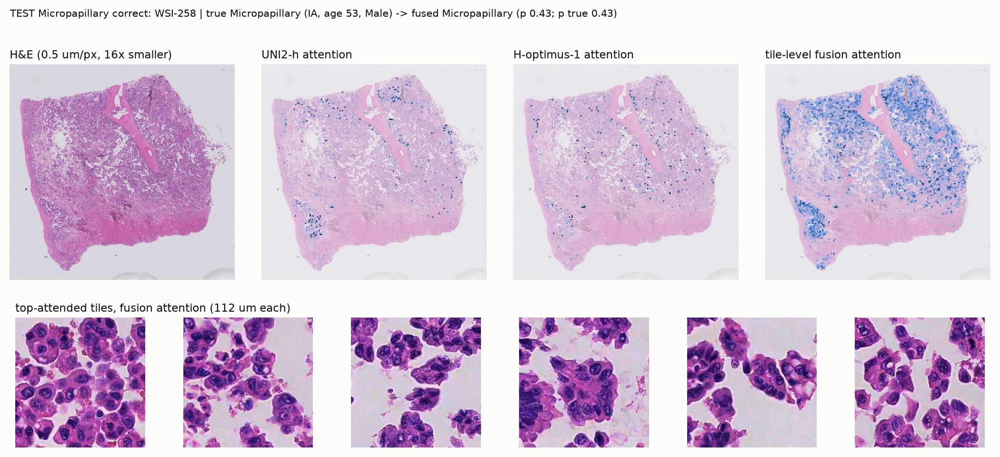

### Micropapillary called Solid

**Micropapillary_called_Solid_WSI-169**

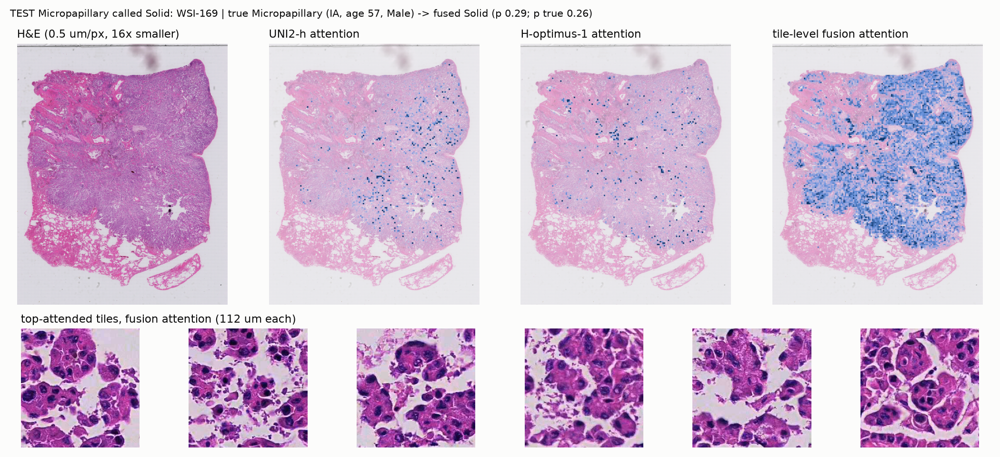

**Micropapillary_called_Solid_WSI-322**

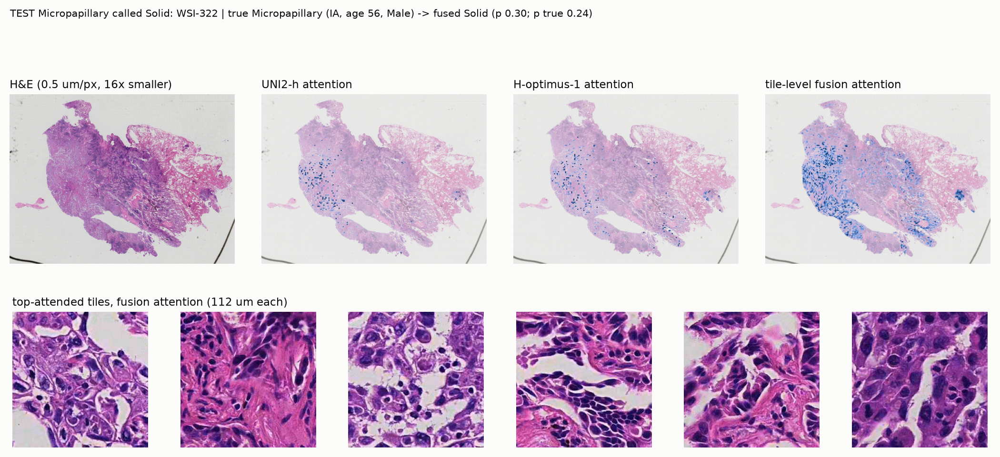

**Solid_correct_WSI-186**

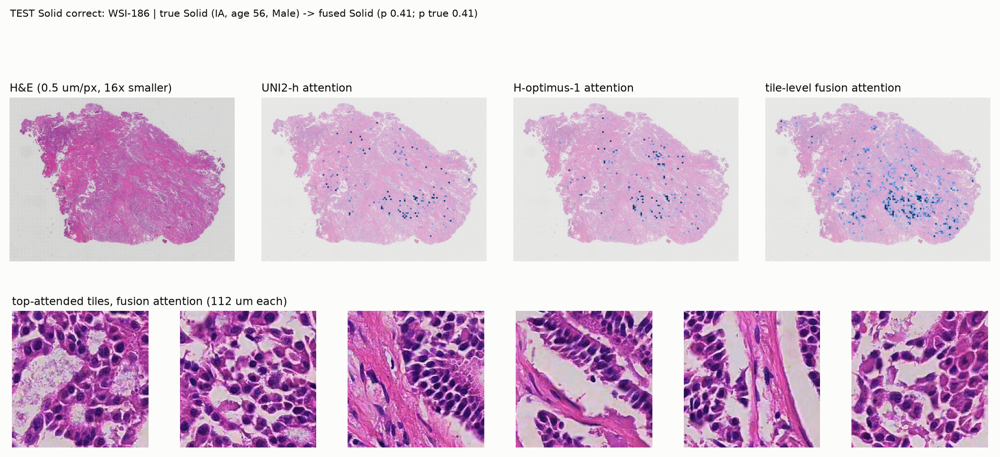

In [13]:
ORDER = [("Lepidic called In situ", "Lepidic correct", "In situ correct"),
         ("Papillary called Micropapillary", "Papillary correct", "Micropapillary correct"),
         ("Micropapillary called Solid", "Solid correct")]
files = sorted((FIG / "failure_test").glob("*.png"))
for group in ORDER:
    display(Markdown(f"### {group[0]}"))
    for tag in group:
        for f in [f for f in files if f.stem.rsplit("_", 1)[0] == tag.replace(" ", "_")]:
            display(Markdown(f"**{f.stem}**")); display(Image(filename=str(f), width=1100))